# Opaque and transparent samples: contrast, absorption and SNR

We compares a fully opaque sample with an absent sample using signal-to-noise ratio (SNR).

| Calculation | Input and sample |
|---|---|
| Empty-interferometer reference | Six heralded inputs; sample absent |
| Attenuation heatmaps | H input; $T_f=(1-p)^2$, $T_s=0$ |
| SNR curves | H input; opaque sample versus absent sample |
| Averaged-absorption comparison | Opaque SNR divided by the square root of absorption averaged over $p$ |

The model uses ideal optical elements and detectors. The SNR uses an independent Poisson-count model. Interferometer probabilities are conditional on successful heralding.

**Conventions:** $n$ is the number of cycles, $N$ is the mean incident photon count in each SNR measurement, and each cycle contains two sample passes. `Tf` and `Ts` are single-pass intensity transmissions. Numerical angles are in radians.



## Basis and operators

The calculation uses the basis $\{|1,H\rangle,|1,V\rangle,|2,H\rangle,|2,V\rangle\}$: path first, imaging polarisation second. `P1` selects the sample path and `P2` the empty input path. At the output, these are ICCD0 and ICCD1.




In [2]:
import numpy as np
import matplotlib.pyplot as plt


def dagger(A):
    return A.conj().T
    
# Identity operator on the two-dimensional spatial/path space {|1>, |2>}
I_spat = np.eye(2, dtype=complex)

# Identity operator on the two-dimensional polarisation space
# (e.g. H/V, D/A, or R/L basis)
I_pol  = np.eye(2, dtype=complex)

# spatial projectors |1><1| and |2><2|

# Projects onto the first basis state
P1 = np.array([[1,0],[0,0]], dtype=complex)

# Projects onto the second basis state
P2 = np.array([[0,0],[0,1]], dtype=complex)

sigma_x = np.array([[0,1],[1,0]], dtype=complex)
sigma_y = np.array([[0,-1j],[1j,0]], dtype=complex)
sigma_z = np.array([[1,0],[0,-1]], dtype=complex)

## Stokes vector to density matrix

`density_from_stokes` constructs

$$\rho=\tfrac12(S_0I+S_1\sigma_z+S_2\sigma_x+S_3\sigma_y).$$

It checks the vector length and physical Stokes limits. By default it normalises the trace to one, ready for use as an input photon. Setting `enforce_normalised=False` keeps the intensity $S_0$ in the trace.


In [3]:
def density_from_stokes(S, enforce_normalised=True, tol=1e-12):
    S = np.asarray(S, dtype=float).flatten()
    if S.size != 4:
        raise ValueError("S must be length-4: (S0,S1,S2,S3).")

    S0, S1, S2, S3 = S

    if S0 < -tol:
        raise ValueError("S0 must be >= 0.")

    if (S1**2 + S2**2 + S3**2) > (S0**2 + 1e-9):
        raise ValueError("Invalid Stokes.")

    # OPTICS convention:
    # S1 = H/V = sigma_z
    # S2 = D/A = sigma_x
    # S3 = R/L = sigma_y
    rho = 0.5 * (S0*I_pol + S1*sigma_z + S2*sigma_x + S3*sigma_y)

    if enforce_normalised:
        tr = np.trace(rho)  # for lossless case, So=Trace(rho)
        if np.abs(tr) < tol:
            raise ValueError("Trace ~ 0; cannot normalise.")
        rho = rho / tr

    return rho

## Density matrix to Stokes vector

`stokes_from_density` performs the reverse conversion by taking traces against $I$, $\sigma_z$, $\sigma_x$ and $\sigma_y$. These give total intensity and the H/V, D/A and R/L intensity differences.



In [4]:
def stokes_from_density(rho, normalise_trace=True, tol=1e-12, warn_tol = 1e-10):
    """
    rho -> S = (S0,S1,S2,S3) using standard mapping with (I,X,Y,Z).
    If normalise_trace=True: scales rho so Tr(rho)=1 before computing.
    """
    rho = np.asarray(rho, dtype=complex)
    if rho.shape != (2,2):
        raise ValueError("rho must be 2x2.")

    tr = np.trace(rho)
    if np.abs(tr) < tol:
        raise ValueError("Trace ~ 0 (no intensity).")

    rho_use = rho / tr if normalise_trace else rho

    def safe_trace(op, label):
        val = np.trace(rho_use @ op)
        if abs(val.imag) > warn_tol:
            print(f"Warning: significant imaginary part in {label}:", val)
        return val.real

    S0 = safe_trace(I_pol, "S0")

    S1 = safe_trace(sigma_z, "S1")  # H/V
    S2 = safe_trace(sigma_x, "S2")  # D/A
    S3 = safe_trace(sigma_y, "S3")  # R/L

    return np.array([S0, S1, S2, S3], dtype=float)

## Heralding the imaging photon

The photon-pair state is ordered as herald polarisation followed by imaging polarisation. For example, $|H,V\rangle$ means a horizontally polarised herald photon and a vertically polarised imaging photon.

The function applies the herald projector, traces out the herald photon, and normalises the remaining imaging state. It returns this state and the probability of the selected herald outcome.


In [5]:
def conditional_imaging_state(rho_pair, herald_projector):
    measurement = np.kron(herald_projector, I_pol)

    postselected = (
        measurement
        @ rho_pair
        @ dagger(measurement)
    )

    p_herald = np.trace(postselected).real

    if p_herald <= 1e-15:
        raise ValueError("Heralding outcome has zero probability.")

    # Indices:
    # herald_row, imaging_row, herald_col, imaging_col
    postselected = postselected.reshape(2, 2, 2, 2)

    # Trace out the herald photon
    rho_imaging = np.trace(
        postselected,
        axis1=0,
        axis2=2,
    )

    rho_imaging = rho_imaging / p_herald

    return rho_imaging, p_herald

## Read the polarisation in one path

This function selects a $2\times2$ polarisation block from the joint $4\times4$ density matrix. Use `path_idx=0` for path 1 (ICCD0) and `path_idx=1` for path 2 (ICCD1).



In [6]:
def stokes_from_4x4_density(rho_4x4, path_idx, normalise_trace=False):
    """
    Extracts Stokes parameters from a 4x4 joint density matrix 
    by selecting the block corresponding to path_idx (0 or 1).
    """
    # 1. Extract the 2x2 block (d0 or d1)
    if path_idx == 0:
        rho_2x2 = rho_4x4[0:2, 0:2] # Top-left block for ICCD 0
    else:
        rho_2x2 = rho_4x4[2:4, 2:4] # Bottom-right block for ICCD 1

    # 2. Use your existing Pauli math on the 2x2 block
    tr = np.trace(rho_2x2)
    
    # If intensity is zero, return zero Stokes vector
    if np.abs(tr) < 1e-15:
        return np.array([0.0, 0.0, 0.0, 0.0])

    # We usually keep normalise_trace=False to see the actual pixel intensity
    rho_use = rho_2x2 / tr if normalise_trace else rho_2x2

    S0 = np.real(np.trace(rho_use @ I_pol))
    S1 = np.real(np.trace(rho_use @ sigma_z))
    S2 = np.real(np.trace(rho_use @ sigma_x))
    S3 = np.real(np.trace(rho_use @ sigma_y))

    return np.array([S0, S1, S2, S3])

## Check a horizontally polarised input

This cell builds a polarisation state as

$$\rho=\begin{pmatrix}a&c\\c^*&1-a\end{pmatrix},$$

with checks that $0\leq a\leq1$ and $|c|^2\leq a(1-a)$. The chosen angles give $a=1$ and $c=0$, so the input is H. It converts the state to Stokes parameters and back; the printed difference should be zero within rounding.

Finally, it combines the polarisation with `P2` to put the photon in the empty input path. Here `theta` is an input-state angle, not the sample-axis angle.


In [7]:
# Imaging photon enters the inner Zeno device in path 2
rho_spat_in = P2.copy()


def rho_from_ac(a, c, check=True, tol=1e-12):
    """
    Build rho = [[a, c],
                 [c*, 1-a]]
    with optional validity checks.
    """
    rho = np.array([[a, c],
                    [np.conj(c), 1 - a]], dtype=complex)
    if check:
        if not (0 - tol <= a <= 1 + tol):
            raise ValueError("a must be in [0, 1].")
        if np.abs(c)**2 > a*(1 - a) + tol:
            raise ValueError("|c|^2 must be <= a(1-a) for PSD.")
    return rho

def is_valid_ac(a, c, tol=1e-12):
    return (0 - tol <= a <= 1 + tol) and (np.abs(c)**2 <= a*(1 - a) + tol)


#Horizontal light a=1, c = 0

theta = 0  # polar angle
phi = 0     # azimuthal angle
a = np.cos(theta/2)**2
c = 0.5 * np.sin(theta) * np.exp(-1j*phi)


rho = rho_from_ac(a, c)

S_in = stokes_from_density(rho)


rho_pol_in = density_from_stokes(S_in, enforce_normalised=True)

rho_tot_in = np.kron(rho_spat_in, rho_pol_in)  # 4x4

print(rho_pol_in - rho_from_ac(a, c, check=True, tol=1e-12))
S_in
#rho_tot_in 

[[0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]


array([1., 1., 0., 0.])

## Prepare H, V, D, A, R and L

The pair is prepared in $|\Phi^+\rangle=(|HH\rangle+|VV\rangle)/\sqrt2$. Herald measurements then prepare six alternative imaging inputs. H, V, D and A keep their labels; heralding R prepares L and heralding L prepares R. The circular convention here is $R=(1,i)/\sqrt2$ and $L=(1,-i)/\sqrt2$.

ThISS cell stores the input states, their Stokes vectors and the herald probabilities, and places each input in path 2. Each selected herald outcome has probability $1/2$. Subsequent interferometer probabilities are conditional on that outcome, so this factor is not multiplied into them.


In [8]:
# Canonical polarisation states
basis_stokes = {
    "H": np.array([1,  1,  0,  0], dtype=float),
    "V": np.array([1, -1,  0,  0], dtype=float),
    "D": np.array([1,  0,  1,  0], dtype=float),
    "A": np.array([1,  0, -1,  0], dtype=float),
    "R": np.array([1,  0,  0,  1], dtype=float),
    "L": np.array([1,  0,  0, -1], dtype=float),
}

# For |Phi+>, these herald outcomes prepare the desired imaging states.
desired_input_to_herald = {
    "H": "H",
    "V": "V",
    "D": "D",
    "A": "A",
    "R": "L",
    "L": "R",
}

# Projectors used by the herald detector and ICCD analysers
basis_projectors = {
    label: density_from_stokes(
        S,
        enforce_normalised=True,
    )
    for label, S in basis_stokes.items()
}

# Bell state |Phi+> = (|HH> + |VV>)/sqrt(2)
H = np.array([1, 0], dtype=complex)
V = np.array([0, 1], dtype=complex)

phi_plus = (
    np.kron(H, H)
    + np.kron(V, V)
) / np.sqrt(2)

rho_pair = np.outer(
    phi_plus,
    phi_plus.conj(),
)

# path 2 is the input/empty path
rho_spat_in = P2.copy()
herald_projectors = basis_projectors.copy()
iccd_analyser_projectors = basis_projectors.copy()

conditional_input_stokes = {}
herald_probabilities = {}
rho_pol_in_list = []
rho_tot_in_list = []

for input_label, herald_label in desired_input_to_herald.items():
    rho_pol_in, p_herald = conditional_imaging_state(
        rho_pair,
        herald_projectors[herald_label],
    )

    S_in = stokes_from_density(
        rho_pol_in,
        normalise_trace=True,
    )

    # Store everything using the imaging input label.
    conditional_input_stokes[input_label] = S_in
    herald_probabilities[input_label] = p_herald
    rho_pol_in_list.append(rho_pol_in)

    rho_tot_in = np.kron(
        rho_spat_in,
        rho_pol_in,
    )

    rho_tot_in_list.append(rho_tot_in)

    print(
        f"Desired imaging input {input_label}: "
        f"use herald result {herald_label}"
    )
    print("Herald probability:", p_herald)
    print("Imaging Stokes vector:", S_in)
    print("Polarization density matrix:")
    print(rho_pol_in)

    print("Total 4x4 density matrix:")
    print(rho_tot_in)
    print()
    

Desired imaging input H: use herald result H
Herald probability: 0.4999999999999999
Imaging Stokes vector: [1. 1. 0. 0.]
Polarization density matrix:
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
Total 4x4 density matrix:
[[0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]]

Desired imaging input V: use herald result V
Herald probability: 0.4999999999999999
Imaging Stokes vector: [ 1. -1.  0.  0.]
Polarization density matrix:
[[0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]
Total 4x4 density matrix:
[[0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 0.+0.j 1.+0.j]]

Desired imaging input D: use herald result D
Herald probability: 0.4999999999999999
Imaging Stokes vector: [1. 0. 1. 0.]
Polarization density matrix:
[[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]
Total 4x4 density matrix:
[[0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0. +0.j 0. +0.j]
 [0. +0.j 0. +0.j 0.5+0.j 0.5+0.j]
 [

## Mix the paths at the beam splitter

Each encounter rotates the path state by $\alpha=\pi/(4n)$, where $n$ is the total number of cycles. `BS_total` applies this path operation while leaving polarisation unchanged. `apply_unitary` updates the density matrix as $U\rho U^\dagger$.

There are two encounters per cycle. With no sample, the $2n$ rotations add to $\pi/2$, transferring the photon from path 2 to path 1. 

In [9]:


def BS_spatial(n_steps):
    angle = np.pi / (4 * n_steps)
    return np.array([[np.cos(angle),  -np.sin(angle)],
                     [np.sin(angle), np.cos(angle)]], dtype=complex)

# lifts the spatial operation into the 4D space.
def BS_total(n_steps):
    return np.kron(BS_spatial(n_steps), I_pol)

def apply_unitary(rho, U):
    return U @ rho @ dagger(U)


## Apply the sample in path 1

The Jones matrix uses `Tf` and `Ts` as single-pass intensity transmissions along the sample's two axes. Their square roots are the amplitude transmissions. `theta_axis` rotates the axes and `delta` adds a relative phase to the second axis; angles are in radians.

`U_object_total` applies this matrix in path 1 and leaves path 2 unchanged. The old “arm 2” comment does not match the implementation. The state is not renormalised after applying the sample, so loss is recorded as a decrease in trace.


In [10]:
# DIATTENUATOR sample in arm 1

def diattenuator_jones(theta_axis, Tf, Ts ,delta=0.0):
    """
    Jones matrix of a diattenuator with axes rotated by theta_axis.
    Tf, Ts are intensity transmissions along its principal axes.
    """
    c, s = np.cos(theta_axis), np.sin(theta_axis)
    R = np.array([[ c,  s],
                  [-s,  c]], dtype=complex)
    Af, As = np.sqrt(Tf), np.sqrt(Ts)
    A = np.array([[Af, 0],
                  [0,  As * np.exp(1j * delta)]], dtype=complex)
    return dagger(R) @ A @ R

def U_object_total(J):
    # Path 1 contains the sample
    # Path 2 is the empty/input path
    return np.kron(P1, J) + np.kron(P2, I_pol)
    
def apply_object(rho, J):
    U = U_object_total(J)
    return U @ rho @ dagger(U)

## One cycle and the full sequence

A cycle applies a beam splitter, two sample passes, then another beam splitter. The mirrors are assumed to be ideal and polarisation independent, and the same Jones matrix is used on both sample passes.

`rho_out_total` repeats the cycle `n_steps` times. The output trace gives the probability that the photon survives the full sequence.


In [11]:
#One complete cycle and full evolution

def cycle_on_rho(rho, n_steps, J_single_pass):
    """
    One physical cycle:

    beam splitter
        -> forward sample pass
        -> mirror
        -> return sample pass
        -> beam splitter

    The mirrors are assumed to be ideal and polarization-independent.
    """
    U_BS = BS_total(n_steps)

    # First beam-splitter interaction
    rho = apply_unitary(rho, U_BS)

    # Forward pass through the sample
    rho = apply_object(rho, J_single_pass)

    # Return pass through the sample
    rho = apply_object(rho, J_single_pass)

    # Second beam-splitter interaction
    rho = apply_unitary(rho, U_BS)

    return rho


def rho_out_total(n_steps, J_single_pass, rho_tot_in):
    """Apply n complete interferometer cycles."""
    if n_steps <= 0:
        raise ValueError("n_steps must be positive.")

    rho = np.asarray(rho_tot_in, dtype=complex).copy()

    for _ in range(n_steps):
        rho = cycle_on_rho(
            rho,
            n_steps,
            J_single_pass,
        )

    return rho


## Choose an absent or present sample

`J_absent` returns the identity, representing an empty sample path. `J_present` builds the sample Jones matrix from the chosen parameters.

The simulation uses `which=0` for the absent sample and `which=1` for the present sample. A present sample can be partially transmitting or opaque; its behaviour depends on `Tf`, `Ts` and `delta`.


In [12]:
# Absent vs present object
# Sample absent: both passes perform the identity
def J_absent():
    return I_pol.copy()


# Sample present: single-pass Jones matrix
def J_present(theta_axis, Tf, Ts, delta=0.0):
    return diattenuator_jones(
        theta_axis=theta_axis,
        Tf=Tf,
        Ts=Ts,
        delta=delta,
    )

## Measure the two outputs

`measure_polarization` calculates an analyser-outcome probability at ICCD0 or ICCD1. `extract_stokes_from_path` combines the six H/V, D/A and R/L outcomes into a Stokes vector for each port.

`simulate_stokes_out` runs the sequence and returns both output Stokes vectors, the survival probability and the final density matrix. The $S_0$ entries give the port probabilities. The function checks that their sum equals survival; absorption is one minus survival.


In [13]:
# Physical analyser states placed before each ICCD
pol_projectors = iccd_analyser_projectors

def measure_polarization(rho_tot, path_idx, pol_basis):
    """
    Measure one polarization intensity at one physical output path.

    path_idx=0 selects physical path 1.
    path_idx=1 selects physical path 2.
    """
    rho_tot = np.asarray(rho_tot, dtype=complex)

    if rho_tot.shape != (4, 4):
        raise ValueError("rho_tot must be 4x4.")

    if path_idx == 0:
        P_spat = P1 
    elif path_idx == 1:
        P_spat = P2
    else:
        raise ValueError("path_idx must be 0 or 1.")

    if pol_basis not in pol_projectors:
        raise ValueError(
            "pol_basis must be H, V, D, A, R, or L."
        )

    P_pol = pol_projectors[pol_basis]

    # Joint path-polarization projector
    P_joint = np.kron(P_spat, P_pol)

    # Unnormalised projected state
    rho_after = (
        P_joint
        @ rho_tot
        @ dagger(P_joint)
    )

    intensity = np.trace(rho_after)

    if abs(intensity.imag) > 1e-10:
        raise ValueError(
            f"Measured intensity has an unexpected "
            f"imaginary part: {intensity}"
        )

    return float(intensity.real)
    

def extract_stokes_from_path(rho_tot, path_idx):
    """
    Takes the 6 required measurements and returns the Stokes vector (S0, S1, S2, S3).
    """
    I_H = measure_polarization(rho_tot, path_idx, 'H')
    I_V = measure_polarization(rho_tot, path_idx, 'V')
    I_D = measure_polarization(rho_tot, path_idx, 'D')
    I_A = measure_polarization(rho_tot, path_idx, 'A')
    I_R = measure_polarization(rho_tot, path_idx, 'R')
    I_L = measure_polarization(rho_tot, path_idx, 'L')
    
    S0 = (I_H + I_V)
    S1 = (I_H - I_V)
    S2 = ( I_D - I_A)
    S3 = (I_R - I_L)
    
    return np.array([S0, S1, S2, S3])

#path_idx = 0  # physical path 1, projector P1, upper-left block
#path_idx = 1  # physical path 2, projector P2, lower-right block

def simulate_stokes_out(
    which,
    n_steps,
    theta_axis,
    Tf,
    Ts,
    delta,
    rho_tot_in,
):
    """
    Run the interferometer and return Stokes vectors
    at both physical output paths.

    which=0: sample absent
    which=1: sample present

    For input prepared in P2:
    The photon begins in path 2.
    With no sample, evolution transfers it to path 1 -> ICCD0.
    For a fully blocking sample and many cycles, surviving
    photons remain predominantly in path 2 -> ICCD1.
    """
    if which == 0:
        J = J_absent()
    elif which == 1:
        J = J_present(theta_axis, Tf, Ts, delta)
    else:
        raise ValueError("which must be 0 or 1.")

    rho_tot_out = rho_out_total(
        n_steps,
        J,
        rho_tot_in,
    )

    S_iccd0 = extract_stokes_from_path(
        rho_tot_out,
        path_idx=0,
    )

    S_iccd1 = extract_stokes_from_path(
        rho_tot_out,
        path_idx=1,
    )

    trace = np.trace(rho_tot_out)

    if abs(trace.imag) > 1e-10:
        raise ValueError(
            f"Output trace has an unexpected imaginary part: {trace}"
        )

    if not np.isclose(
        S_iccd0[0] + S_iccd1[0],
        trace.real,
        atol=1e-10,
        rtol=0,
    ):
        raise ValueError(
            "Detector intensities do not match total survival."
        )

    return S_iccd0, S_iccd1, float(trace.real), rho_tot_out

## Run the empty-interferometer reference

This cell propagates all six prepared inputs through 100 cycles with `which=0`, so the sample is absent. It stores and prints the two output Stokes vectors and their sum.

For this ideal reference, the photon reaches ICCD0 with unit probability, up to rounding, and retains its input polarisation. ICCD1 is empty. The supplied sample parameters are not used when `which=0`.


In [14]:
# Simulation parameters
n_steps = 100
theta_axis = 0#np.deg2rad(130)

Tf = 1
Ts = 1.0
delta = 0.0

all_outputs_iccd0 = []
all_outputs_iccd1 = []
all_outputs_total = []

# Run six separate experiments: H, V, D, A, R, L
for label, rho_in in zip(conditional_input_stokes.keys(),rho_tot_in_list):
    S_iccd0, S_iccd1, tr, rho_out = simulate_stokes_out(
        which=0,
        n_steps=n_steps,
        theta_axis=theta_axis,
        Tf=Tf,
        Ts=Ts,
        delta=delta,
        rho_tot_in=rho_in,
    )

    all_outputs_iccd0.append(S_iccd0)
    all_outputs_iccd1.append(S_iccd1)

    # Sum of the Stokes vectors from both output paths
    S_total = S_iccd0 + S_iccd1
    all_outputs_total.append(S_total)

    print(f"{label} input")
    print("ICCD0:", S_iccd0)
    print("ICCD1:", S_iccd1)
    print("Total:", S_total)
    print("Remaining probability:", tr)
    print()

H input
ICCD0: [1. 1. 0. 0.]
ICCD1: [3.90698032e-16 3.90698032e-16 0.00000000e+00 0.00000000e+00]
Total: [1. 1. 0. 0.]
Remaining probability: 0.9999999999999808

V input
ICCD0: [ 1. -1.  0.  0.]
ICCD1: [ 3.90698032e-16 -3.90698032e-16  0.00000000e+00  0.00000000e+00]
Total: [ 1. -1.  0.  0.]
Remaining probability: 0.9999999999999808

D input
ICCD0: [1. 0. 1. 0.]
ICCD1: [3.90698032e-16 0.00000000e+00 3.90698032e-16 0.00000000e+00]
Total: [1. 0. 1. 0.]
Remaining probability: 0.9999999999999808

A input
ICCD0: [ 1.  0. -1.  0.]
ICCD1: [ 3.90698032e-16  0.00000000e+00 -3.90698032e-16  0.00000000e+00]
Total: [ 1.  0. -1.  0.]
Remaining probability: 0.9999999999999808

R input
ICCD0: [1. 0. 0. 1.]
ICCD1: [3.90698032e-16 0.00000000e+00 0.00000000e+00 3.90698032e-16]
Total: [1. 0. 0. 1.]
Remaining probability: 0.9999999999999808

L input
ICCD0: [ 1.  0.  0. -1.]
ICCD1: [ 3.90698032e-16  0.00000000e+00  0.00000000e+00 -3.90698032e-16]
Total: [ 1.  0.  0. -1.]
Remaining probability: 0.9999999999

## Reconstruct the effective output maps

The six input Stokes vectors form the columns of `S_inputs`. For each output port, the cell calculates

$$M=S_{\mathrm{out}}S_{\mathrm{in}}^+,$$

where $+$ denotes the pseudoinverse. These Mueller matrices describe the complete interferometer response at each port, rather than the sample alone.

The stored outputs come from the empty-interferometer run. Thus `M_iccd0` should be the identity, `M_iccd1` should be zero, and their sum `M_total` should be the identity within numerical precision.


In [15]:
# Columns: H, V, D, A, R, L
S_inputs = np.column_stack(
    list(conditional_input_stokes.values())
)

def reconstruct_mueller(output_stokes):
    S_outputs = np.column_stack(output_stokes)
    return S_outputs @ np.linalg.pinv(S_inputs)

M_iccd0 = reconstruct_mueller(all_outputs_iccd0)
M_iccd1 = reconstruct_mueller(all_outputs_iccd1)

# Both camera outputs combined
M_total = M_iccd0 + M_iccd1
M_total

array([[1.00000000e+00, 2.68031548e-16, 5.20972094e-17, 0.00000000e+00],
       [2.77555756e-17, 1.00000000e+00, 4.01149243e-17, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 1.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.00000000e+00]])

## A helper for calculating output Mueller matrices

`get_mueller` runs all six inputs for any supplied sample parameters and cycle count, reconstructs a Mueller matrix for each port, and returns their sum as well.

This cell defines the helper but does not call it. The later heatmaps and SNR calculations use `simulate_stokes_out` directly.


In [16]:
S_in_matrix = np.column_stack(list(conditional_input_stokes.values()))
S_in_pinv = np.linalg.pinv(S_in_matrix)


def get_mueller(which, n_steps, theta_axis, Tf, Ts, delta):
    all_outputs_iccd0 = []
    all_outputs_iccd1 = []

    for rho_in in rho_tot_in_list:
        S_iccd0, S_iccd1, tr, _ = simulate_stokes_out(
            which,  # Use the specified sample
            n_steps=n_steps,
            theta_axis=theta_axis,
            Tf=Tf,
            Ts=Ts,
            delta=delta,
            rho_tot_in=rho_in,
        )

        all_outputs_iccd0.append(S_iccd0)
        all_outputs_iccd1.append(S_iccd1)

    # Each column is an unnormalised output Stokes vector

    M_iccd0 = reconstruct_mueller(all_outputs_iccd0)
    M_iccd1 = reconstruct_mueller(all_outputs_iccd1)
    M_total = M_iccd0 + M_iccd1

    return M_iccd0, M_iccd1, M_total


## Colour map and physicality checks

This cell defines the blue-to-yellow colour gradient and functions for checking the effective Mueller maps. A Mueller matrix is converted to a Choi matrix, whose eigenvalues test complete positivity. The partial trace checks that the map does not increase the photon probability; equality to the identity indicates trace preservation.

`print_physicality` displays the results. 


In [17]:
from matplotlib.colors import LinearSegmentedColormap

mathematica_cmap = LinearSegmentedColormap.from_list(
    "mathematica_cmap",
    [
        (0.0, (0.148, 0.330, 0.540)),
        (0.1, (0.274, 0.400, 0.658)),
        (0.5, (0.900, 0.620, 0.290)),
        (0.9, (1.000, 0.870, 0.600)),
        (1.0, (1.000, 0.950, 0.750)),
    ],
    N=2001,
)
# (S0, S1, S2, S3) <-> (I, sigma_z, sigma_x, sigma_y)
pauli_basis = [I_pol, sigma_z, sigma_x, sigma_y]


def choi_from_mueller(M):
    """
    Construct the unnormalised 4x4 Choi matrix of the effective
    two-dimensional polarization map represented by M.
    """
    M = np.asarray(M, dtype=complex)

    if M.shape != (4, 4):
        raise ValueError("M must be a 4x4 Mueller matrix.")

    # I_M(alpha_k) = sum_j M[j,k] alpha_j
    mapped_basis = [
        sum(M[j, k] * pauli_basis[j] for j in range(4))
        for k in range(4)
    ]

    A, B, C, D = mapped_basis

    # J_I = 1/2 [[A+B, C+iD], [C-iD, A-B]]
    return 0.5 * np.block([
        [A + B, C + 1j * D],
        [C - 1j * D, A - B],
    ])


def partial_trace_output(J_choi):
    """
    Compute Tr_output(J_choi), using the tensor ordering
    input tensor output.
    """
    J_choi = np.asarray(J_choi, dtype=complex)

    if J_choi.shape != (4, 4):
        raise ValueError("J_choi must be a 4x4 matrix.")

    # Tensor indices:
    # (input_row, output_row, input_col, output_col)
    J_tensor = J_choi.reshape(2, 2, 2, 2)

    return np.trace(
        J_tensor,
        axis1=1,
        axis2=3,
    )


def check_mueller_physicality(M, tol=1e-9):
    """
    Check whether a Mueller matrix defines a completely positive,
    trace-non-increasing effective polarization map.
    """
    J_choi = choi_from_mueller(M)

    hermitian_error = np.linalg.norm(
        J_choi - dagger(J_choi),
        ord="fro",
    )
    is_hermitian = hermitian_error <= tol

    # Remove only numerical anti-Hermitian round-off before eigendecomposition.
    J_hermitian = 0.5 * (
        J_choi + dagger(J_choi)
    )
    choi_eigenvalues = np.linalg.eigvalsh(J_hermitian)

    completely_positive = (
        is_hermitian
        and np.min(choi_eigenvalues) >= -tol
    )

    # T = Tr_output(J).  A physical lossy map requires T <= I.
    T = partial_trace_output(J_hermitian)
    T = 0.5 * (T + dagger(T))

    loss_operator = I_pol - T
    loss_eigenvalues = np.linalg.eigvalsh(loss_operator)

    trace_non_increasing = (
        np.min(loss_eigenvalues) >= -tol
    )
    trace_preserving = np.allclose(
        T,
        I_pol,
        atol=tol,
        rtol=0,
    )

    return {
        "choi_matrix": J_choi,
        "choi_eigenvalues": choi_eigenvalues,
        "hermitian_error": hermitian_error,
        "completely_positive": completely_positive,
        "partial_trace_output": T,
        "loss_operator_eigenvalues": loss_eigenvalues,
        "trace_non_increasing": trace_non_increasing,
        "trace_preserving": trace_preserving,
        "physical_lossy_map": (
            completely_positive
            and trace_non_increasing
        ),
    }


def print_physicality(name, check):
    print(f"\nPhysicality check: {name}")
    print("Choi eigenvalues:", check["choi_eigenvalues"])
    print("Completely positive:", check["completely_positive"])
    print("Tr_output(J):\n", check["partial_trace_output"])
    print(
        "Eigenvalues of I - Tr_output(J):",
        check["loss_operator_eigenvalues"],
    )
    print("Trace non-increasing:", check["trace_non_increasing"])
    print("Trace preserving:", check["trace_preserving"])
    print("Physical lossy map:", check["physical_lossy_map"])



## Sweep attenuation and find equal absorption

This cell uses an H-polarised input in path 2 and runs a $100\times100$ grid: 100 attenuation values $p\in[0,1]$ and cycle counts $n=1,\ldots,100$. The present sample has

$$T_f=(1-p)^2,\qquad T_s=0,\qquad\theta_{\mathrm{axis}}=\delta=0.$$

Because the input is H and the axes are aligned, it probes the $T_f$ component. At $p=0$ this component is fully transmitting; at $p=1$ the whole sample is opaque. The parameter $p$ is an amplitude attenuation parameter, not an absorption probability.

The cell stores the port contrast and total protocol absorption:

$$D=\frac{P(\mathrm{ICCD0})-P(\mathrm{ICCD1})}{P(\mathrm{ICCD0})+P(\mathrm{ICCD1})},\qquad P_{\mathrm{abs}}=1-P_{\mathrm{surv}}.$$

It then uses an equivalent two-path H-input model and `brentq` to find $p^*(n)$ where the protocol absorption equals the single-pass value $1-(1-p)^2$. The root search is performed for $n>1$; the $n=1$ entry is left as `NaN`. Each cycle in the reduced model includes two sample passes.


In [18]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from matplotlib.colors import LinearSegmentedColormap

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 9,
})

mathematica_cmap = LinearSegmentedColormap.from_list(
    "mathematica_cmap",
    [
        (0.0, (0.148, 0.330, 0.540)),
        (0.1, (0.274, 0.400, 0.658)),
        (0.5, (0.900, 0.620, 0.290)),
        (0.9, (1.000, 0.870, 0.600)),
        (1.0, (1.000, 0.950, 0.750)),
    ],
    N=2001,
)

# Exactly 100 attenuation values and 100 cycle counts.
original_p_values = np.linspace(0.0, 1.0, 100)
original_n_values = np.arange(1, 101)

# H-polarised photon entering empty path 2.
original_rho_input = np.kron(
    np.array([[0, 0], [0, 1]], dtype=complex),
    np.array([[1, 0], [0, 0]], dtype=complex),
)

original_discrimination = np.zeros((100, 100))
original_absorption = np.zeros((100, 100))

for j, cycle_count in enumerate(original_n_values):
    for k, p_value in enumerate(original_p_values):
        stokes0, stokes1, survival, _ = simulate_stokes_out(
            which=1,
            n_steps=int(cycle_count),
            theta_axis=0.0,
            Tf=(1.0 - p_value)**2,
            Ts=0.0,
            delta=0.0,
            rho_tot_in=original_rho_input,
        )

        probability0 = float(stokes0[0])
        probability1 = float(stokes1[0])

        # Original notebook's detector ordering.
        original_discrimination[j, k] = (
            (probability0 - probability1)
            / (probability0 + probability1)
        )

        original_absorption[j, k] = 1.0 - survival

    if cycle_count % 10 == 0:
        print(f"Completed {cycle_count}/100 cycle counts")


# Calculate the crossover using the equivalent two-path H-input model.
# This avoids repeating the full polarisation simulation during root finding.
def absorption_difference(p, n):
    angle = np.pi / (4 * n)

    beam_splitter = np.array([
        [np.cos(angle), -np.sin(angle)],
        [np.sin(angle),  np.cos(angle)],
    ])

    # Two passes: amplitude transmission (1-p)^2 per cycle.
    double_pass = np.diag([(1.0 - p)**2, 1.0])

    cycle = beam_splitter @ double_pass @ beam_splitter

    output = (
        np.linalg.matrix_power(cycle, int(n))
        @ np.array([0.0, 1.0])
    )

    protocol_absorption = 1.0 - np.vdot(output, output).real
    single_pass_absorption = 1.0 - (1.0 - p)**2

    return protocol_absorption - single_pass_absorption


original_p_star = np.full(100, np.nan)

for j, cycle_count in enumerate(original_n_values):
    # At n=1 there is no nonzero interior crossover.
    if cycle_count > 1:
        original_p_star[j] = brentq(
            absorption_difference,
            1e-5,
            1.0 - 1e-8,
            args=(int(cycle_count),),
            xtol=1e-12,
        )

print(f"Crossover at n=100: p* = {original_p_star[-1]:.6f}")

Completed 10/100 cycle counts
Completed 20/100 cycle counts
Completed 30/100 cycle counts
Completed 40/100 cycle counts
Completed 50/100 cycle counts
Completed 60/100 cycle counts
Completed 70/100 cycle counts
Completed 80/100 cycle counts
Completed 90/100 cycle counts
Completed 100/100 cycle counts
Crossover at n=100: p* = 0.102001


## Plot the output-port contrast (discrimination )

This heatmap shows the stored contrast $D$ against attenuation $p$ and cycle count $n$. Positive values favour ICCD0 and negative values favour ICCD1; $D=0$ means equal port probabilities among surviving photons.


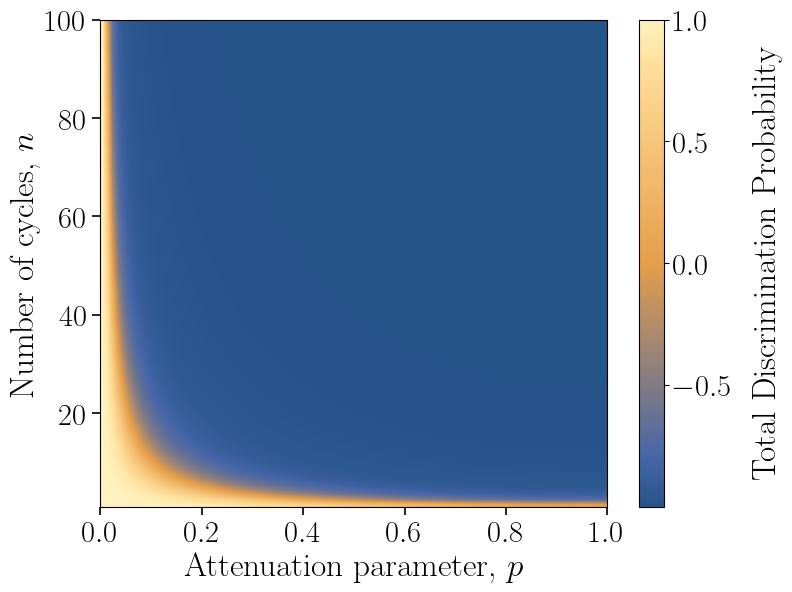

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    original_discrimination,
    extent=[0, 1, 1, 100],
    origin="lower",
    aspect="auto",
    cmap=mathematica_cmap,
    interpolation="bilinear",
)

# White outline beneath the dashed crossover curve.
'''ax.plot(
    original_p_star,
    original_n_values,
    color="white",
    linewidth=3.5,
)
ax.plot(
    original_p_star,
    original_n_values,
    color="black",
    linestyle="--",
    linewidth=2,
    label=r"$p^*(n)$: equal absorption",
)'''

colourbar = fig.colorbar(image, ax=ax)
colourbar.set_label(
    "Total Discrimination Probability",
    fontsize=24,
    labelpad=14,
)
colourbar.ax.tick_params(labelsize=22)

ax.set_xlabel(
    r"Attenuation parameter, $p$",
    fontsize=24,
)


ax.set_ylabel(r"Number of cycles, $n$", fontsize=24)
ax.set_xlim(0, 1)
ax.set_ylim(1, 100)



ax.tick_params(
    axis="both",
    labelsize=22,
    length=6,
    width=1.2,
    direction="out",
)

#ax.legend(loc="upper right", fontsize=12)

fig.tight_layout()
fig.savefig(
    "Discrim-1.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,)

plt.show()

## Plot absorption and its crossover with a single pass

This heatmap shows the total probability of absorption during the protocol. The black dashed curve, outlined in white, marks $p^*(n)$, where protocol absorption equals single-pass absorption for the same H input.



p* at n=100 = 0.102001


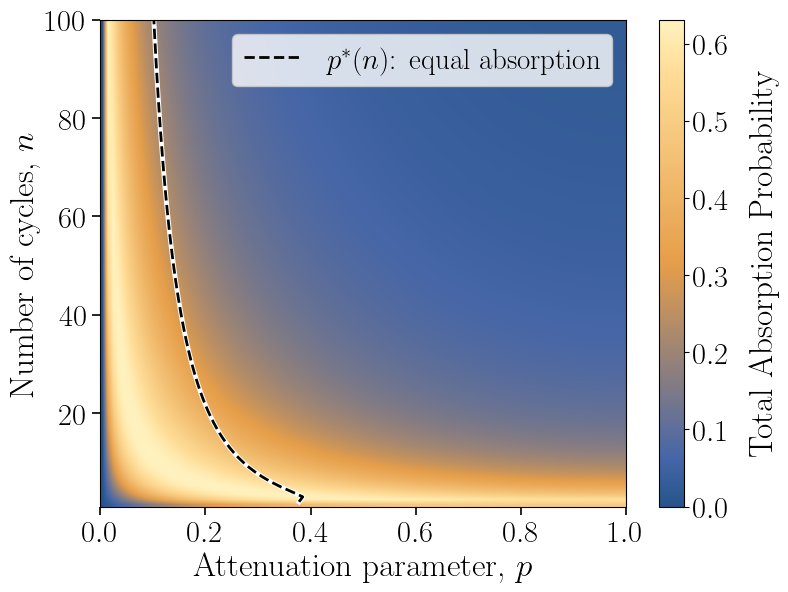

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))

image = ax.imshow(
    original_absorption,
    extent=[0, 1, 1, 100],
    origin="lower",
    aspect="auto",
    cmap=mathematica_cmap,
    interpolation="bilinear",
)

ax.plot(
    original_p_star,
    original_n_values,
    color="white",
    linewidth=3.5,
)
ax.plot(
    original_p_star,
    original_n_values,
    color="black",
    linestyle="--",
    linewidth=2,
    label=r"$p^*(n)$: equal absorption",
)

colourbar = fig.colorbar(image, ax=ax)

colourbar.set_label(
    "Total Absorption Probability",
    fontsize=24,
    labelpad=14,
)

colourbar.ax.tick_params(labelsize=22)

ax.set_xlabel(
    r"Attenuation parameter, $p$",
    fontsize=24,
)


ax.set_ylabel(r"Number of cycles, $n$", fontsize=24)
ax.set_xlim(0, 1)
ax.set_ylim(1, 100)

ax.tick_params(
    axis="both",
    labelsize=22,
    length=6,
    width=1.2,
    direction="out",
)
ax.legend(loc="upper right", fontsize=21)

fig.tight_layout()
fig.savefig(
    "TotAbsorbed-1.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)
print(f"p* at n=100 = {original_p_star[-1]:.6f}")
plt.show()

## Compare opaque and absent samples using SNR

`snr_statistics` simulates the same input with the sample absent and present. Its defaults use H in path 2 and a fully opaque present sample, $T_f=T_s=0$. It returns the detector-probability differences, their Poisson variance coefficients and the present-sample absorption.

`SNR(n)` calculates

$$f(n)=\frac{|\Delta P_0-\Delta P_1|}{\sqrt{P_0^{\mathrm{absent}}+P_1^{\mathrm{absent}}+P_0^{\mathrm{present}}+P_1^{\mathrm{present}}}},$$

where $\Delta P_j=P_j^{\mathrm{absent}}-P_j^{\mathrm{present}}$. This assumes independent Poisson detector counts. With mean incident count $N$ in each run ($2N$ across both runs), the SNR is $\sqrt{N}\,f(n)$. The cell calculates $f(n)$ over 1–100 cycles.




Opaque sample: SNR(1) = 0.816497
Opaque sample: SNR(100) = 1.405549
0.024192515147509197


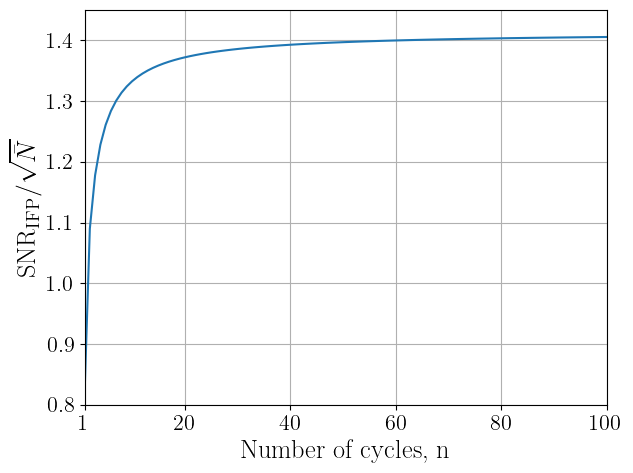

In [25]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 9,
})

def snr_statistics(n, rho_in=None, theta_axis=0.0, Tf=0.0, Ts=0.0, delta=0.0):
    if int(n) != n or n < 1:
        raise ValueError("n must be a positive integer.")
    n = int(n)
    if rho_in is None:
        # Same input as the heatmaps: photon in path 2, H polarisation.
        rho_in = np.kron(
            np.array([[0, 0], [0, 1]], dtype=complex),
            np.array([[1, 0], [0, 0]], dtype=complex),
        )

    absent0, absent1, _, _ = simulate_stokes_out(
        which=0, n_steps=n, theta_axis=theta_axis,
        Tf=Tf, Ts=Ts, delta=delta, rho_tot_in=rho_in,
    )
    present0, present1, present_survival, _ = simulate_stokes_out(
        which=1, n_steps=n, theta_axis=theta_axis,
        Tf=Tf, Ts=Ts, delta=delta, rho_tot_in=rho_in,
    )

    P_absent = np.array([absent0[0], absent1[0]], dtype=float)
    P_present = np.array([present0[0], present1[0]], dtype=float)
    if not np.all(np.isfinite(np.r_[P_absent, P_present])):
        raise ValueError("Non-finite detector probabilities.")
    if np.any(np.r_[P_absent, P_present] < -1e-10):
        raise ValueError("Negative detector probability.")
    P_absent = np.clip(P_absent, 0, 1)
    P_present = np.clip(P_present, 0, 1)

    differences = P_absent - P_present
    variances = P_absent + P_present
    return {
        "P_absent": P_absent,
        "P_present": P_present,
        "P_absorbed": float(np.clip(1.0 - present_survival, 0.0, 1.0)),
        "DeltaD0": differences[0],
        "DeltaD1": differences[1],
        "Sigma2D0": variances[0],
        "Sigma2D1": variances[1],
    }


def SNR(n, **sample_parameters):
    stats = snr_statistics(n, **sample_parameters)
    denom = np.sqrt(stats["Sigma2D0"] + stats["Sigma2D1"])
    return (
        abs(stats["DeltaD0"] - stats["DeltaD1"]) / denom
        if denom != 0 else 0.0
    )


snr_n_values = np.arange(1, 101)
# Defaults compare absent object with a completely opaque object.
snr_values = np.array([SNR(n) for n in snr_n_values])
print(f"Opaque sample: SNR(1) = {snr_values[0]:.6f}")
print(f"Opaque sample: SNR(100) = {snr_values[-1]:.6f}")
print(snr_statistics(100)["P_absorbed"])
plt.figure()
plt.plot(snr_n_values, snr_values)
plt.xlabel("Number of cycles, n", fontsize=19)
plt.ylabel(r"$\mathrm{SNR}_{\mathrm{IFP}}/\sqrt{\bar{N}}$", fontsize=19)
plt.tick_params(axis='both', labelsize=16)
plt.grid(True)
plt.xlim(1, 100)
plt.ylim(0.8, 1.45)
plt.xticks([1, 20, 40, 60, 80, 100])
plt.tight_layout()
plt.savefig('NoOuterSNR-1.pdf', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

# Example for another sample (not plotted above):
# SNR(100, theta_axis=0.0, Tf=0.5, Ts=0.5)

## Normalise SNR by opaque-sample absorption

`SNR_per_sqrt_absorbed` uses the same sample and input for the SNR and its absorption probability, then calculates

$$g_{\mathrm{opaque}}(n)=\frac{f(n)}{\sqrt{P_{\mathrm{abs,opaque}}(n)}}=\frac{\mathrm{SNR}}{\sqrt{N_{\mathrm{abs}}}},\qquad N_{\mathrm{abs}}=N P_{\mathrm{abs,opaque}}.$$

It returns `NaN` when absorption is effectively zero. The cell evaluates the fully opaque sample over 1–100 cycles and prints its absorption and both SNR coefficients at 100 cycles.


In [26]:
from matplotlib.ticker import MaxNLocator



plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 9,
})

def SNR_per_sqrt_absorbed(n, **sample_parameters):
    stats = snr_statistics(n, **sample_parameters)
    P_absorbed = stats["P_absorbed"]
    if P_absorbed <= 1e-12:
        return np.nan

    # This is the same probability-based SNR calculation as SNR(n).
    signal = abs(stats["DeltaD0"] - stats["DeltaD1"])
    noise = np.sqrt(stats["Sigma2D0"] + stats["Sigma2D1"])
    snr_normalised = signal / noise if noise != 0 else 0.0

    return snr_normalised / np.sqrt(P_absorbed)


# 100 cycle counts; fully opaque sample, as in the preceding SNR plot.
snr_abs_n_values = np.arange(1, 101)
snr_abs_sample = dict(theta_axis=0.0, Tf=0.0, Ts=0.0, delta=0.0)
snr_abs_values = np.array([
    SNR_per_sqrt_absorbed(int(n), **snr_abs_sample)
    for n in snr_abs_n_values
])

stats100 = snr_statistics(100, **snr_abs_sample)
print(f"At n=100: P_absorbed = {stats100['P_absorbed']:.8f}")
print(f"SNR/sqrt(N) = {SNR(100, **snr_abs_sample):.6f}")
print(f"SNR/sqrt(N_abs) = {snr_abs_values[-1]:.6f}")


At n=100: P_absorbed = 0.02419252
SNR/sqrt(N) = 1.405549
SNR/sqrt(N_abs) = 9.036606


## Use absorption averaged over attenuation

This cell calculates protocol absorption for every attenuation value on the same 100-point $p$ grid and takes the arithmetic mean:

$$\overline{P}_{\mathrm{abs}}(n)=\frac{1}{100}\sum_{k=1}^{100}P_{\mathrm{abs}}(p_k,n).$$

The two-path model uses amplitude transmission $1-p$ per sample pass, so the two-pass amplitude factor is $(1-p)^2$. It stores the full absorption grid and the mean at each cycle count.

The numerator remains the **opaque-versus-absent** SNR coefficient $f(n)$. The reported curve is $f(n)/\sqrt{\overline{P}_{\mathrm{abs}}(n)}$. This mixes an opaque-sample signal with absorption averaged across different attenuations.

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Same attenuation grid and denominator as pabsAvg in the all-computations notebook.
averaged_p_values = original_p_values.copy()
averaged_abs_denominator = len(averaged_p_values) 
# For the ordinary arithmetic mean on this grid, use instead:
# averaged_abs_denominator = len(averaged_p_values)

averaged_snr_n_values = np.arange(1, 101)


def protocol_absorption_for_average(p, n):
    """Whole-protocol absorption for amplitude transmission 1-p per pass."""
    beam_splitter = BS_spatial(int(n))
    double_sample_pass = np.diag([(1.0 - p)**2, 1.0])
    one_cycle = beam_splitter @ double_sample_pass @ beam_splitter
    output = (
        np.linalg.matrix_power(one_cycle, int(n))
        @ np.array([0.0, 1.0])  # photon starts in empty path 2
    )
    return float(np.clip(1.0 - np.vdot(output, output).real, 0.0, 1.0))


# Keep each attenuation's absorption available for inspection.
averaged_absorption_grid = np.array([
    [protocol_absorption_for_average(p, n) for p in averaged_p_values]
    for n in averaged_snr_n_values
])

averaged_absorption_values = (
    np.sum(averaged_absorption_grid, axis=1) / averaged_abs_denominator
)

# Same fully opaque versus absent SNR numerator as the earlier plots.
# H input in path 2 matches the attenuation calculation above.
averaged_rho_input = np.kron(
    np.array([[0, 0], [0, 1]], dtype=complex),
    np.array([[1, 0], [0, 0]], dtype=complex),
)
averaged_incident_snr_values = np.array([
    SNR(
        int(n), rho_in=averaged_rho_input,
        theta_axis=0.0, Tf=0.0, Ts=0.0, delta=0.0,
    )
    for n in averaged_snr_n_values
])

averaged_abs_snr_values = np.divide(
    averaged_incident_snr_values,
    np.sqrt(averaged_absorption_values),
    out=np.full_like(averaged_incident_snr_values, np.nan),
    where=averaged_absorption_values > 1e-12,
)

print(f"Attenuation samples: {len(averaged_p_values)}; denominator: {averaged_abs_denominator:g}")
print(f"At n=100: averaged absorption = {averaged_absorption_values[-1]:.8f}")
print(f"SNR/sqrt(N) = {averaged_incident_snr_values[-1]:.6f}")
print(f"SNR normalised by sqrt(averaged absorption) = {averaged_abs_snr_values[-1]:.6f}")



Attenuation samples: 100; denominator: 100
At n=100: averaged absorption = 0.08165730
SNR/sqrt(N) = 1.405549
SNR normalised by sqrt(averaged absorption) = 4.918678


## Check ICCD1 and the combined surviving map

Tests are applied to `M_iccd1` and to `M_iccd0 + M_iccd1`. For the empty-interferometer reference, ICCD1 is a zero map: it is completely positive and trace non-increasing, but not trace preserving. The combined map should preserve trace.

Adding the two maps describes all surviving photons while discarding which output port they reached.


In [28]:
print_physicality(
    "ICCD1 map",
    check_mueller_physicality(M_iccd1),
)

print_physicality(
    "Surviving map",
    check_mueller_physicality(M_iccd0 + M_iccd1),
)


Physicality check: ICCD1 map
Choi eigenvalues: [2.31963705e-32 5.05907556e-32 1.53899528e-31 7.81396065e-16]
Completely positive: True
Tr_output(J):
 [[3.90698032e-16+0.j 2.03542772e-32+0.j]
 [2.03542772e-32+0.j 3.90698032e-16+0.j]]
Eigenvalues of I - Tr_output(J): [1. 1.]
Trace non-increasing: True
Trace preserving: False
Physical lossy map: True

Physicality check: Surviving map
Choi eigenvalues: [1.53760040e-16 3.95484105e-16 4.94777258e-16 2.00000000e+00]
Completely positive: True
Tr_output(J):
 [[1.00000000e+00+0.j 5.20972094e-17+0.j]
 [5.20972094e-17+0.j 1.00000000e+00+0.j]]
Eigenvalues of I - Tr_output(J): [1.86457170e-14 1.91018658e-14]
Trace non-increasing: True
Trace preserving: True
Physical lossy map: True


## Compare the two absorption normalisations

This figure places the two stored curves side by side. The left panel uses opaque-sample absorption, $f(n)/\sqrt{P_{\mathrm{abs,opaque}}(n)}$. The right uses absorption averaged over attenuation, $f(n)/\sqrt{\overline{P}_{\mathrm{abs}}(n)}$.

Both use the same opaque-versus-absent signal coefficient, and the panels share their axis scales. Only the left curve uses the absorption of the same sample that produces its signal. The shared plot label is shorthand for these normalised coefficients. 


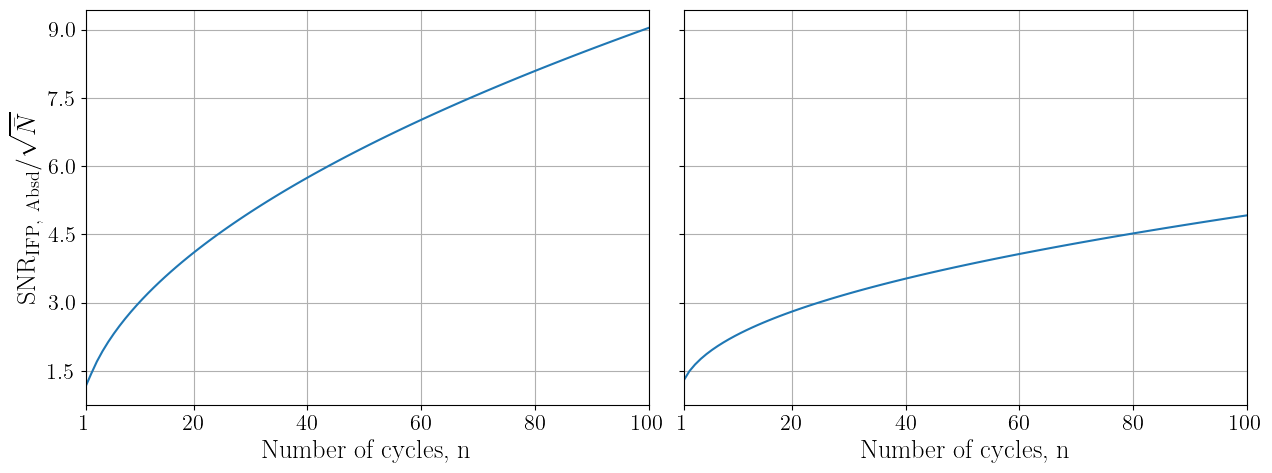

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.8, 4.8),
    sharex=True,
    sharey=True,
)

# Left: opaque-sample absorption.
axes[0].plot(snr_abs_n_values, snr_abs_values)

# Right: absorption averaged over p.
axes[1].plot(averaged_snr_n_values, averaged_abs_snr_values)

for ax in axes:
    ax.set_xlabel("Number of cycles, n", fontsize=19)
    ax.tick_params(axis="both", labelsize=16)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=8))
    ax.grid(True)
    ax.set_xlim(1, 100)
    ax.set_xticks([1, 20, 40, 60, 80, 100])

axes[0].set_ylabel(
    r"$\mathrm{SNR}_{\mathrm{IFP}, \ \mathrm{Absd}}/\sqrt{\bar{N}}$",
    fontsize=19,
)

fig.tight_layout()

fig.savefig(
    "snr_absorbed_side_by_side.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.show()

## Read both normalised values at 100 cycles

This cell finds the index corresponding to $n=100$ in each stored cycle array and prints the two plotted values: the opaque-absorption normalisation and the attenuation-averaged absorption normalisation.

In [30]:
opaque_index = np.flatnonzero(np.asarray(snr_abs_n_values) == 100)[0]
averaged_index = np.flatnonzero(
    np.asarray(averaged_snr_n_values) == 100
)[0]

print(f"Opaque at n=100: {snr_abs_values[opaque_index]:.6f}")
print(f"Averaged at n=100: {averaged_abs_snr_values[averaged_index]:.6f}")

Opaque at n=100: 9.036606
Averaged at n=100: 4.918678


## Recalculate the opaque result at 100 cycles

This cell explicitly defines `sample_parameters` for a fully opaque sample and recalculates the result at $n=100$. It prints the incident-photon SNR coefficient $f(n)$, the protocol absorption probability, and $g_{\mathrm{opaque}}(n)=f(n)/\sqrt{P_{\mathrm{abs}}}$.

This is an independent call to the same simulation functions, providing a numerical check against the stored opaque curve. It is also where the `sample_parameters` variable used by the earlier diagnostic print is first defined.


In [31]:
n = 100

# Fully opaque sample.
sample_parameters = dict(
    theta_axis=0.0,
    Tf=0.0,
    Ts=0.0,
    delta=0.0,
)

stats = snr_statistics(n, **sample_parameters)

f_n = SNR(n, **sample_parameters)
P_absorbed = stats["P_absorbed"]
g_opaque = f_n / np.sqrt(P_absorbed)

print(f"n = {n}")
print(f"f(n) = {f_n:.6f}")
print(f"P_absorbed, opaque = {P_absorbed:.8f}")
print(f"g_opaque(n) = {g_opaque:.6f}")

n = 100
f(n) = 1.405549
P_absorbed, opaque = 0.02419252
g_opaque(n) = 9.036606


# ------------------------------- THE END -----------------------------------